# Proyek Klasifikasi Gambar: Fashion MNIST
- **Nama:** Namira Assalwa
- **Email:** ae128b6x1327@student.devacademy.id
- **ID Dicoding:** AE128B6X1327

## Import Semua Packages/Library yang Digunakan

In [1]:
import os
import json
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

import tensorflow as tf
from tensorflow.keras import datasets, layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

print("Library berhasil diimpor! Versi TensorFlow:", tf.__version__)

Library berhasil diimpor! Versi TensorFlow: 2.21.0


## Data Preparation

### Data Loading

In [2]:
# Load dataset Fashion-MNIST bawaan (train dan test mentah)
(X_train_raw, y_train_raw), (X_test_raw, y_test_raw) = datasets.fashion_mnist.load_data()

# Gabungkan seluruh data agar pembagian dataset bisa dilakukan secara mandiri sesuai kriteria
X_all = np.concatenate((X_train_raw, X_test_raw), axis=0)
y_all = np.concatenate((y_train_raw, y_test_raw), axis=0)

print(f"Total seluruh data gabungan: {X_all.shape[0]} gambar")

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Total seluruh data gabungan: 70000 gambar


### Data Preprocessing

#### Split Dataset

In [3]:
# Normalisasi nilai piksel ke rentang [0, 1]
X_all = X_all / 255.0

# Tambahkan dimensi channel (karena grayscale, channel = 1 -> (28, 28, 1))
X_all = np.expand_dims(X_all, -1)

# Bagi dataset secara mandiri:
# 1. Pisahkan 20% untuk Test Set, sisa 80% untuk Train & Validation
X_train_val, X_test, y_train_val, y_test = train_test_split(X_all, y_all, test_size=0.2, random_state=42)

# 2. Dari 80% sisa tadi, pisahkan lagi 20% untuk Validation Set
X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.2, random_state=42)

# Cetak bentuk masing-masing subset dataset
print(f"Bentuk Train Set       : {X_train.shape}")
print(f"Bentuk Validation Set  : {X_val.shape}")
print(f"Bentuk Test Set        : {X_test.shape}")

# Opsional: Data Augmentation untuk train set
train_datagen = ImageDataGenerator(
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True
)
train_datagen.fit(X_train)

Bentuk Train Set       : (44800, 28, 28, 1)
Bentuk Validation Set  : (11200, 28, 28, 1)
Bentuk Test Set        : (14000, 28, 28, 1)


## Modelling

In [4]:
model = models.Sequential([
    layers.Conv2D(64, (3, 3), activation='relu', padding='same', input_shape=(28, 28, 1)),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.3),

    layers.GlobalAveragePooling2D(),
    layers.Dense(512, activation='relu'),
    layers.Dropout(0.4),
    layers.Dense(10, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │        66,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 146,442 (572.04 KB)

 Trainable params: 146,058 (570.54 KB)

 Non-trainable params: 384 (1.50 KB)

## Evaluasi dan Visualisasi

Epoch 1/35
700/700 ━━━━━━━━━━━━━━━━━━━━ 267s 382ms/step - accuracy: 0.8671 - loss: 0.3634 - val_accuracy: 0.8821 - val_loss: 0.3192 - learning_rate: 1.0000e-04
Epoch 2/35
700/700 ━━━━━━━━━━━━━━━━━━━━ 263s 376ms/step - accuracy: 0.8667 - loss: 0.3598 - val_accuracy: 0.8637 - val_loss: 0.3642 - learning_rate: 1.0000e-04
Epoch 3/35
700/700 ━━━━━━━━━━━━━━━━━━━━ 264s 377ms/step - accuracy: 0.8685 - loss: 0.3592 - val_accuracy: 0.8793 - val_loss: 0.3311 - learning_rate: 1.0000e-04
Epoch 4/35
700/700 ━━━━━━━━━━━━━━━━━━━━ 265s 379ms/step - accuracy: 0.8681 - loss: 0.3600 - val_accuracy: 0.8827 - val_loss: 0.3211 - learning_rate: 1.0000e-04
Epoch 5/35
700/700 ━━━━━━━━━━━━━━━━━━━━ 266s 380ms/step - accuracy: 0.8674 - loss: 0.3584 - val_accuracy: 0.8721 - val_loss: 0.3410 - learning_rate: 1.0000e-04
Epoch 6/35
700/700 ━━━━━━━━━━━━━━━━━━━━ 265s 379ms/step - accuracy: 0.8703 - loss: 0.3565 - val_accuracy: 0.8736 - val_loss: 0.3444 - learning_rate: 1.0000e-04
Epoch 7/35
700/700 ━━━━━━━━━━━━━━━━━━━━ 

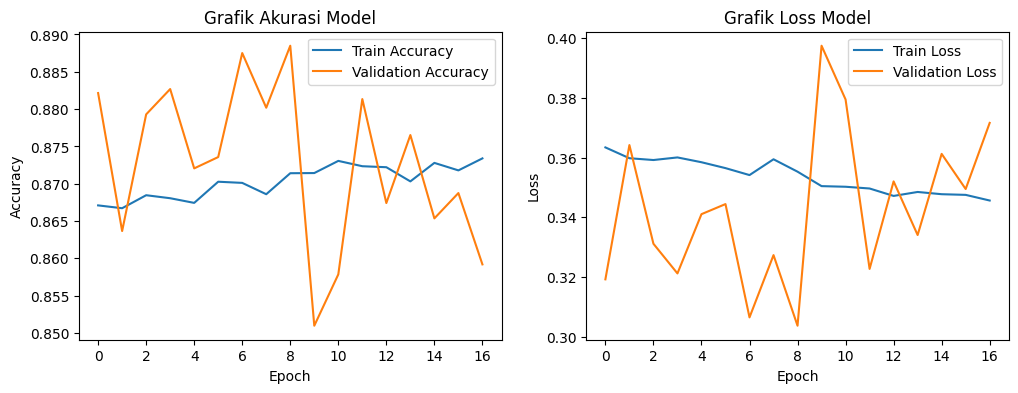

In [6]:
callbacks = [
    EarlyStopping(monitor='val_accuracy', patience=8, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=2, min_lr=0.0001)
]

# Training model
history = model.fit(
    train_datagen.flow(X_train, y_train, batch_size=64),
    epochs=35,
    validation_data=(X_val, y_val),
    callbacks=callbacks
)

# Evaluasi pada Test Set
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=2)
print(f"\nAkurasi pada Testing Set: {test_acc * 100:.2f}%")

# Plot Akurasi dan Loss
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Grafik Akurasi Model')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Grafik Loss Model')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.show()

## Konversi Model

In [7]:
# 1. Simpan format Keras / SavedModel
model.save('model_fashion.keras')
model.export('saved_model')
print("Model berhasil disimpan ke format .keras dan SavedModel!")

# 2. Konversi ke TFLite
converter = tf.lite.TFLiteConverter.from_saved_model('saved_model')
tflite_model = converter.convert()
os.makedirs('tflite', exist_ok=True)
with open('tflite/model.tflite', 'wb') as f:
    f.write(tflite_model)
print("File 'model.tflite' berhasil dibuat!")

# 3. Buat file label.txt di dalam folder tflite
labels = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]
with open('tflite/label.txt', 'w') as f:
    f.write("\n".join(labels))
print("File 'label.txt' berhasil dibuat di folder tflite!")

# 4. Konversi ke TensorFlow.js (TFJS)
os.makedirs('tfjs_model', exist_ok=True)
temp_weights_path = 'tfjs_model/model.weights.h5'
model.save_weights(temp_weights_path)
final_bin_path = 'tfjs_model/group1-shard1of1.bin'
if os.path.exists(temp_weights_path):
    os.rename(temp_weights_path, final_bin_path)

weights_manifest_entry = []
for w in model.weights:
    w_name = w.name if hasattr(w, 'name') else str(w)
    w_shape = w.shape.as_list() if hasattr(w, 'shape') else []
    w_dtype = w.dtype.name if hasattr(w.dtype, 'name') else str(w.dtype)
    weights_manifest_entry.append({"name": w_name, "shape": w_shape, "dtype": w_dtype})

model_json = model.to_json()
tfjs_manifest = {
    "modelTopology": json.loads(model_json),
    "weightsManifest": [{"paths": ["group1-shard1of1.bin"], "weights": weights_manifest_entry}]
}
with open('tfjs_model/model.json', 'w') as f:
    json.dump(tfjs_manifest, f)
print("Folder 'tfjs_model' beserta model.json berhasil dibuat!")

Saved artifact at 'saved_model'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 28, 28, 1), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 10), dtype=tf.float32, name=None)
Captures:
  132527072612176: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132527072613520: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132527072612944: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132527072611984: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132527072610640: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132527072613136: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132527072612368: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132527072614288: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132527072613904: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132527072613712: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132527072612560: Ten

## Inference (Optional)

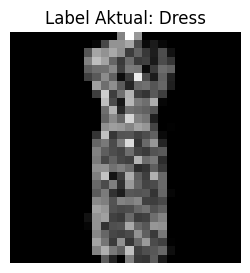

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 159ms/step
Hasil Prediksi Model : Dress
Tingkat Keyakinan    : 97.11%


In [10]:
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

# Pilih sampel acak dari data testing
index = 10
sample_image = X_test[index]

plt.figure(figsize=(3, 3))
plt.imshow(sample_image.reshape(28, 28), cmap='gray')
plt.title(f"Label Aktual: {class_names[y_test[index]]}")
plt.axis('off')
plt.show()

# Prediksi
prediction = model.predict(np.expand_dims(sample_image, 0))
predicted_class = np.argmax(prediction)

print(f"Hasil Prediksi Model : {class_names[predicted_class]}")
print(f"Tingkat Keyakinan    : {np.max(prediction) * 100:.2f}%")